# 15. Causal / Merchandising theo Label

Phân tích display và mailer context của các product household đã mua trong 90 ngày trước cutoff.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from propensity.eda.merchandising_label import (
    load_merchandising_label_report,
)
from propensity.eda.merchandising_label_plots import (
    plot_merchandising_positive_rates,
)

## 1. Build leakage-safe merchandising features

In [2]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

raw_dir = project_root / "data" / "raw" / "Dunnhumby"
label_path = (
    project_root
    / "data"
    / "processed"
    / "purchase_propensity_t90_h7_step7"
    / "household_cutoff_labels.parquet"
)

report = load_merchandising_label_report(
    label_path,
    raw_dir,
    observation_days=90,
)

## 2. Định nghĩa exposure

Transaction được join `causal_data` theo `PRODUCT_ID + STORE_ID + WEEK_NO`.

| Feature | Định nghĩa |
|---|---|
| `ever_display_exposure_90d` | Có mua ít nhất một product–store–week với `display != '0'` |
| `ever_mailer_exposure_90d` | Có mua ít nhất một product–store–week với `mailer != '0'` |

In [3]:
report.summary_by_label

,feature,label,n_mapped_observations,missing_mapping_rate,exposure_rate
0,ever_display_exposure_90d,0,71997,0.240706,0.912969
1,ever_display_exposure_90d,1,103811,0.033624,0.976168
2,ever_mailer_exposure_90d,0,71997,0.240706,0.964471
3,ever_mailer_exposure_90d,1,103811,0.033624,0.991369


## 3. Positive rate theo display và mailer exposure

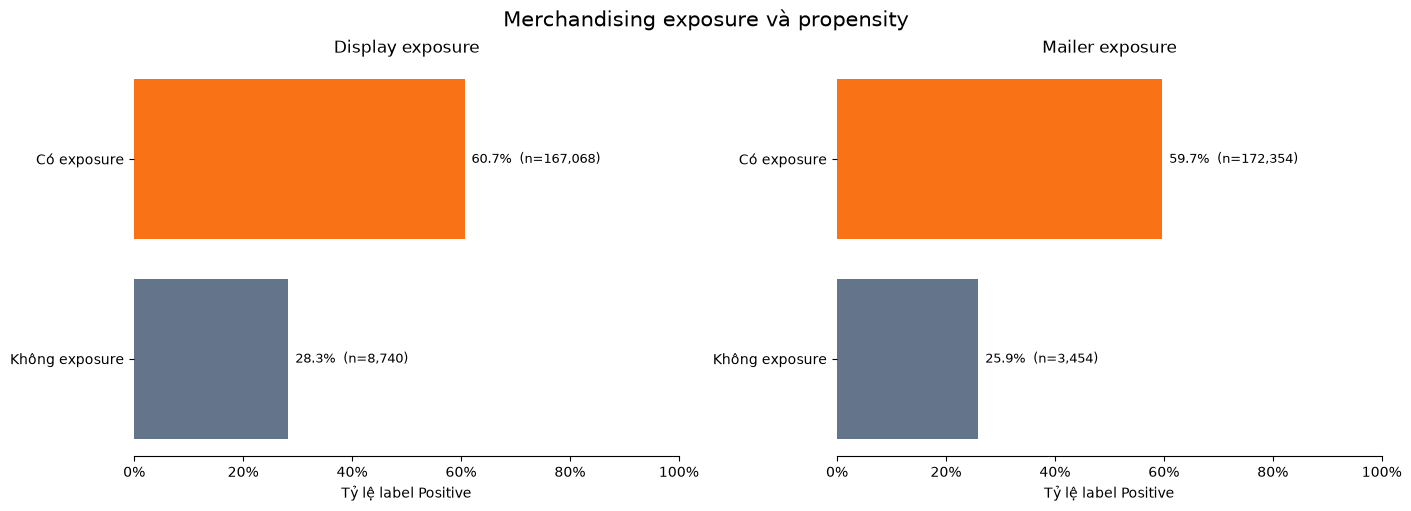

In [4]:
merchandising_figure = plot_merchandising_positive_rates(
    report.feature_panel
)
plt.show()

## Lưu ý diễn giải

- Feature chỉ dùng transaction trong `[cutoff-90, cutoff-1]`.
- Household không có purchase line map được causal giữ exposure là null và không tham gia so sánh.
- Các mã khác `0` chỉ được hiểu là có merchandising context; không diễn giải thứ hạng giữa các mã.
- Đây là exposure gắn với product đã mua, không phải bằng chứng household thực sự nhìn thấy display hoặc mailer.
- Association quan sát được không phải causal lift của merchandising.